In [1]:
import numpy as np
import matplotlib.pyplot as plt
import sys
sys.path.append("..")
from lens.raytrace import sag, normal_angle, refract_at, hit_surface, trace, cross, best_spot

In [2]:
print(cross(6, [(0, 25, 1.5), (5, np.inf, 1.0)]))
print(cross(0.01, [(0, 25, 1.5), (5, np.inf, 1.0)]))

50.82618325253521
51.66666437037028


In [3]:
n, R1, R2, t = 1.5, 50, -50, 5
f = 1 / ((n - 1) * (1 / R1 - 1 / R2 + (n - 1) * t / (n * R1 * R2)))
print(f, t + f * (1 - (n - 1) * t / (n * R1)))
print(cross(0.01, [(0, 50, 1.5), (5, - 50, 1.0)]))

50.847457627118644 54.152542372881356
54.15253924976858


In [4]:
heights = np.arange(1, 11)
print(np.round(cross(heights, [(0, np.inf, 1.5), (5, -25, 1.0)]), 2))
print(np.round(cross(heights, [(0, 25, 1.5), (5, np.inf, 1.0)]), 2))

[54.91 54.64 54.18 53.54 52.71 51.67 50.43 48.95 47.23 45.24]
[51.64 51.57 51.46 51.3  51.09 50.83 50.52 50.15 49.73 49.26]


the spread is more in the flipped lens

In [5]:
lenses = {
    "plano-convex": [(0, 25, 1.5), (5, np.inf, 1.0)],
    "flipped":      [(0, np.inf, 1.5), (5, -25, 1.0)],
    "biconvex":     [(0, 50, 1.5), (5, -50, 1.0)],
}
rays = np.linspace(-10, 10, 1001)
sensors = np.linspace(35, 60, 501)

for name, surfaces in lenses.items():
    z_last, y, u = trace(rays, surfaces)
    spots = []
    for z in sensors:
        y_sensor = y + np.tan(u) * (z - z_last)
        spots.append(np.sqrt(np.mean(y_sensor ** 2)))
    spots = np.array(spots)
    best = np.argmin(spots)
    print(f"{name}: best focus {sensors[best]:.2f} mm, RMS spot {spots[best]:.4f} mm")

plano-convex: best focus 50.20 mm, RMS spot 0.0765 mm
flipped: best focus 49.05 mm, RMS spot 0.3243 mm
biconvex: best focus 52.15 mm, RMS spot 0.1024 mm


plano-convex lens: the curve at the front bends the ray partly and the back surface bends the already bent ray a little more. bot bends are gentle.

flipped lens: flat rays pass through the normal with angle of incidence = 0 and the curved back does all the bending, so there is a lot more spherical aberration!

biconvex lens: better than flipped lens, but performs worse than plano-convex lens.

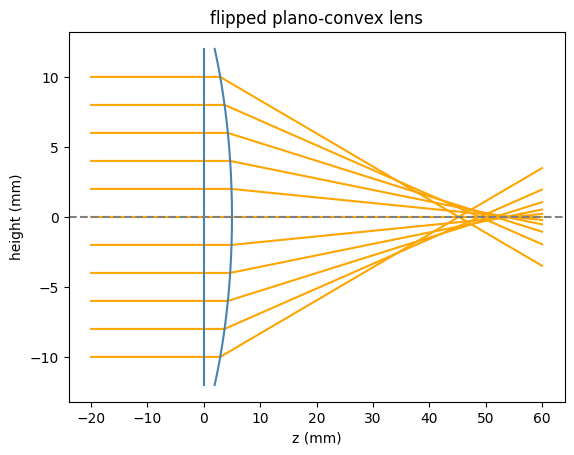

In [6]:
surfaces = [(0, np.inf, 1.5), (5, -25, 1.0)]

for h in np.linspace(-10, 10, 11):
    z_last, y, u = trace(h, surfaces)
    y_end = y + np.tan(u) * (60 - z_last)
    plt.plot([-20, 0, z_last, 60], [h, h, y, y_end], color="orange")

ys = np.linspace(-12, 12, 200)
plt.plot(0 + sag(ys, np.inf), ys, color="steelblue")
plt.plot(5 + sag(ys, -25), ys, color="steelblue")
plt.axhline(0, color="gray", linestyle="--")
plt.xlabel("z (mm)"); plt.ylabel("height (mm)")
plt.title("flipped plano-convex lens")
plt.show()

the rays pass straight through the flat front, then bend only at the curved back, which bulges toward the right. The edge rays cross the axis much earlier than the center rays: the crossings are spread from about 45 to 55 instead of 49 to 51.6.